# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Viral Songs Dataset](https://www.kaggle.com/datasets/vedauv/what-makes-a-song-go-viral-10000-tracks/data)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('viral_songs.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,track_00002,Track_00002,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1
2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
3,track_00004,Track_00004,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0
4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1


## last Five row

In [4]:
df.tail()

,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
9995,track_09996,Track_09996,Artist_1357,Latin,2011,184,0.786,0.774,0.778,91.4,0.000,0.216,0.273,0.287,-6.35,1865425,1
9996,track_09997,Track_09997,Artist_0123,Classical,2012,165,0.463,0.381,0.631,79.0,0.943,0.000,0.215,0.178,-8.22,186073,0
9997,track_09998,Track_09998,Artist_0504,Rock,2014,242,0.567,0.842,0.611,132.1,0.384,0.124,0.203,0.344,-11.01,55762,0
9998,track_09999,Track_09999,Artist_0801,Hip-Hop,2012,165,0.815,0.901,0.569,91.2,0.124,0.000,0.125,0.061,-7.52,3710114,1
9999,track_10000,Track_10000,Artist_1393,Jazz,2025,312,0.500,0.446,0.510,101.5,0.560,0.137,0.178,0.221,-8.97,149232,0


## Shape of our dataset

In [5]:
df.shape

(10000, 17)

## List out all columns

In [6]:
df.columns

Index(['track_id', 'track_name', 'artist', 'genre', 'release_year',
       'duration_sec', 'danceability', 'energy', 'valence', 'tempo_bpm',
       'acousticness', 'instrumentalness', 'speechiness', 'liveness',
       'loudness_db', 'streams', 'viral'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

track_id             object
track_name           object
artist               object
genre                object
release_year          int64
duration_sec          int64
danceability        float64
energy              float64
valence             float64
tempo_bpm           float64
acousticness        float64
instrumentalness    float64
speechiness         float64
liveness            float64
loudness_db         float64
streams               int64
viral                 int64
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          10000 non-null  object 
 1   track_name        10000 non-null  object 
 2   artist            10000 non-null  object 
 3   genre             10000 non-null  object 
 4   release_year      10000 non-null  int64  
 5   duration_sec      10000 non-null  int64  
 6   danceability      10000 non-null  float64
 7   energy            10000 non-null  float64
 8   valence           10000 non-null  float64
 9   tempo_bpm         10000 non-null  float64
 10  acousticness      10000 non-null  float64
 11  instrumentalness  10000 non-null  float64
 12  speechiness       10000 non-null  float64
 13  liveness          10000 non-null  float64
 14  loudness_db       10000 non-null  float64
 15  streams           10000 non-null  int64  
 16  viral             10000 non-null  int64  

## Check Null Value

In [9]:
df.isnull().sum()

track_id            0
track_name          0
artist              0
genre               0
release_year        0
duration_sec        0
danceability        0
energy              0
valence             0
tempo_bpm           0
acousticness        0
instrumentalness    0
speechiness         0
liveness            0
loudness_db         0
streams             0
viral               0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,1.000000e+04,10000.00000
mean,2017.499400,208.776800,0.611709,0.651938,0.582280,110.975940,0.295583,0.177337,0.087453,0.184925,-7.975896,2.415685e+06,0.36050
std,4.607854,49.967024,0.192612,0.187686,0.177984,19.017206,0.263574,0.161221,0.069674,0.114307,2.976277,9.721026e+06,0.48017
min,2010.000000,60.000000,0.000000,0.005000,0.000000,50.000000,0.000000,0.000000,0.000000,0.000000,-18.740000,1.340000e+02,0.00000
25%,2013.000000,175.000000,0.482000,0.529000,0.459000,98.000000,0.085000,0.017000,0.027000,0.099000,-9.980000,8.671450e+04,0.00000
50%,2018.000000,209.000000,0.624000,0.669000,0.582000,111.300000,0.235000,0.154000,0.080000,0.180000,-7.980000,3.290580e+05,0.00000
75%,2022.000000,242.000000,0.753000,0.787000,0.703000,124.500000,0.441000,0.288000,0.134000,0.264000,-5.990000,1.343092e+06,1.00000
max,2025.000000,433.000000,1.000000,1.000000,1.000000,177.800000,1.000000,0.934000,0.381000,0.623000,0.000000,4.430683e+08,1.00000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

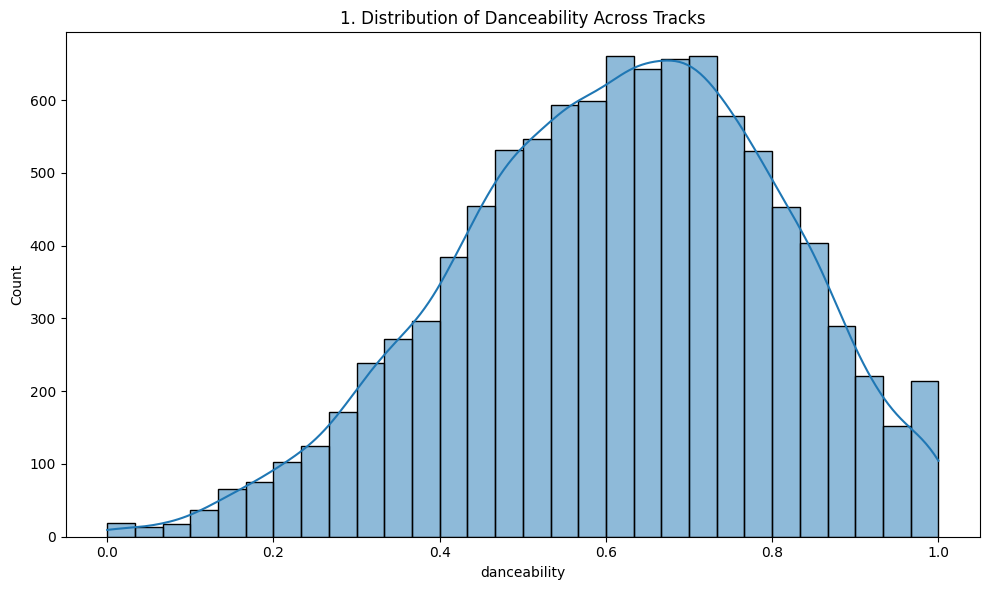

In [13]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='danceability', bins=30, kde=True)
plt.title(f'{plot_no}. Distribution of Danceability Across Tracks')
show_fig()
plot_no += 1

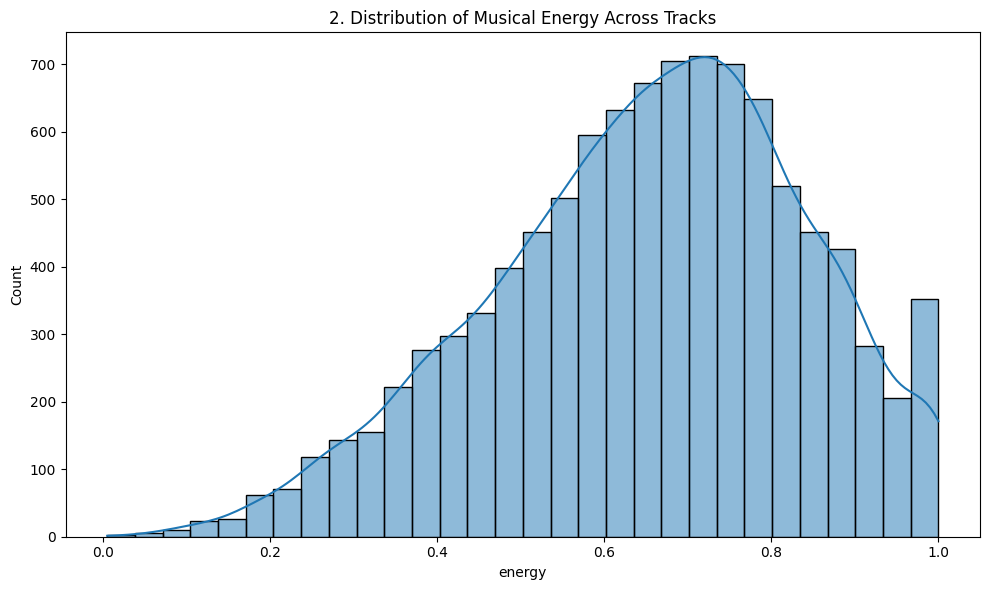

In [14]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='energy', bins=30, kde=True)
plt.title(f'{plot_no}. Distribution of Musical Energy Across Tracks')
show_fig()
plot_no += 1

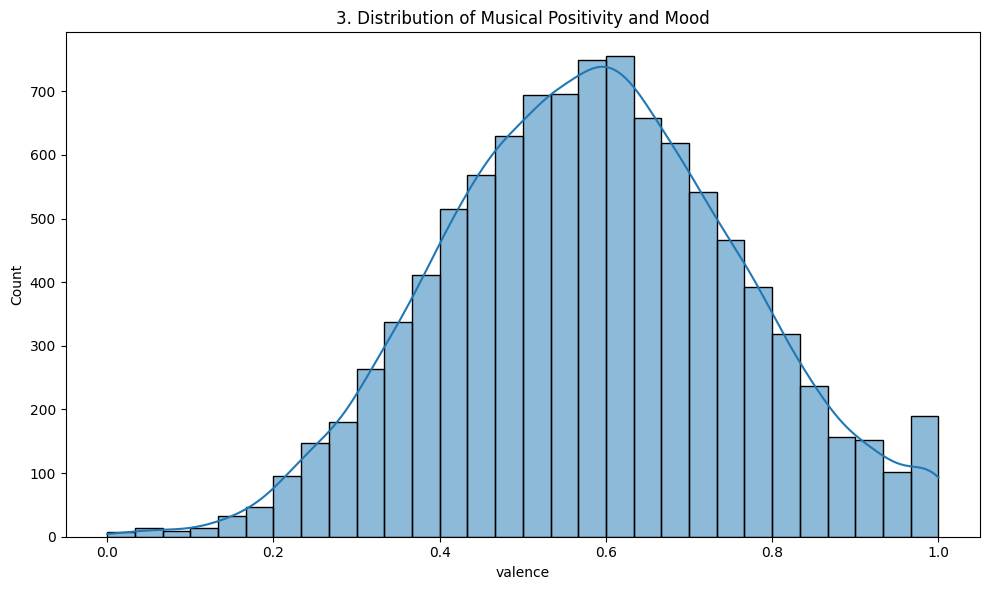

In [15]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='valence', bins=30, kde=True)
plt.title(f'{plot_no}. Distribution of Musical Positivity and Mood')
show_fig()
plot_no += 1

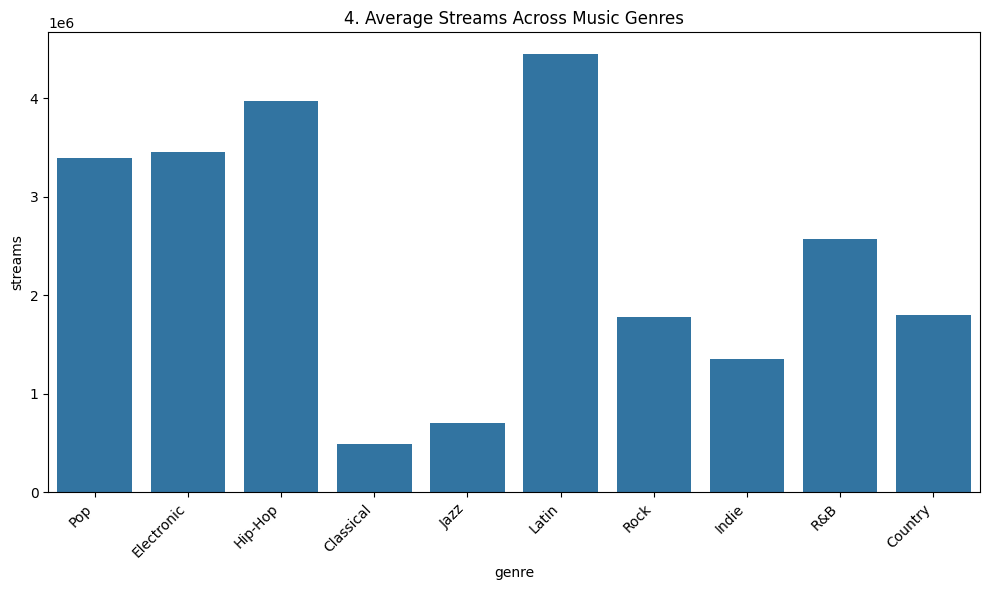

In [16]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='genre', y='streams', errorbar=None, estimator='mean')
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Average Streams Across Music Genres')
show_fig()
plot_no += 1

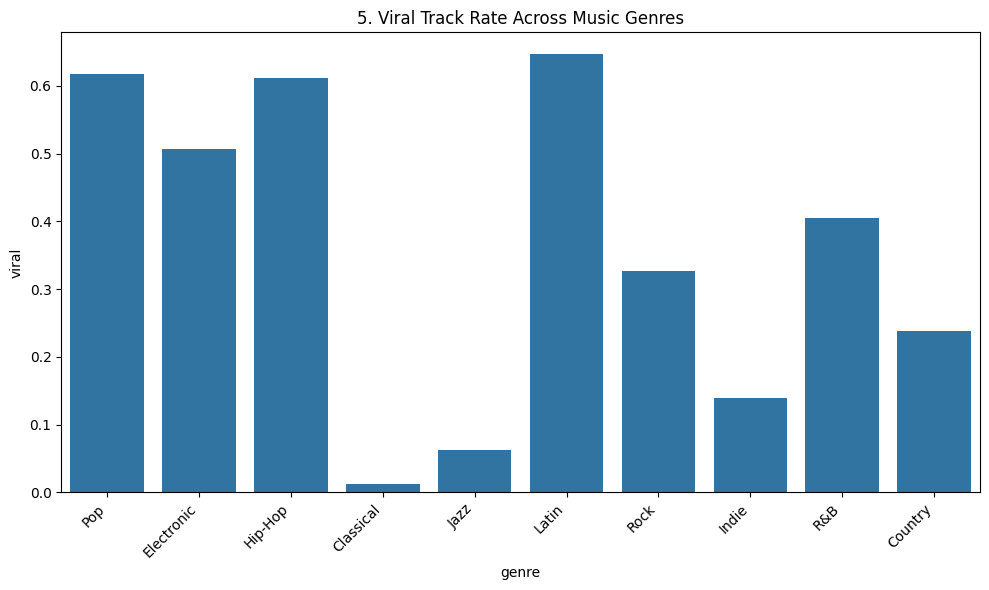

In [17]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='genre', y='viral', errorbar=None, estimator='mean')
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Viral Track Rate Across Music Genres')
show_fig()
plot_no += 1

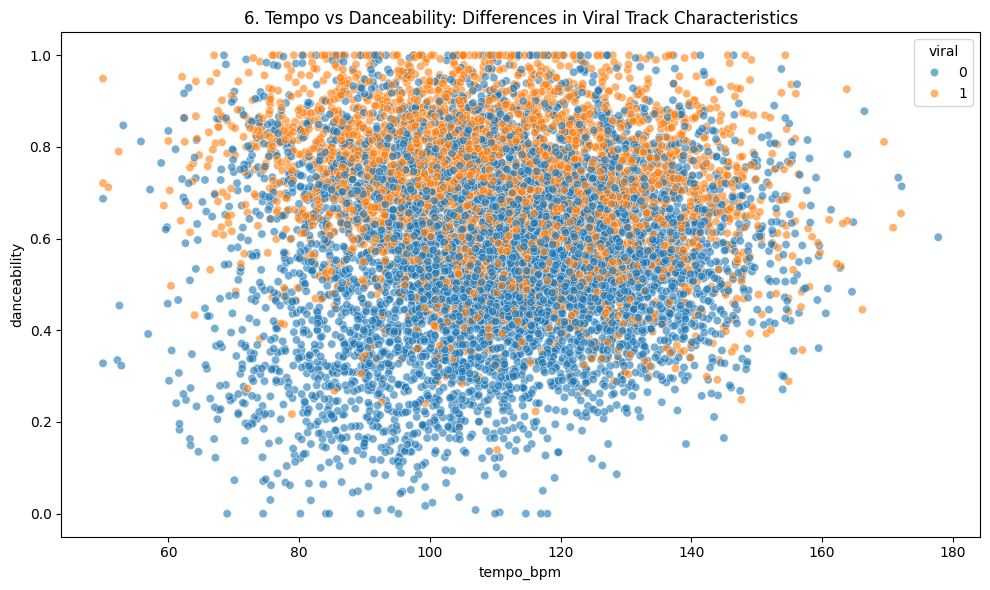

In [18]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='tempo_bpm', y='danceability', hue='viral', alpha=0.6)
plt.title(f'{plot_no}. Tempo vs Danceability: Differences in Viral Track Characteristics')
show_fig()
plot_no += 1

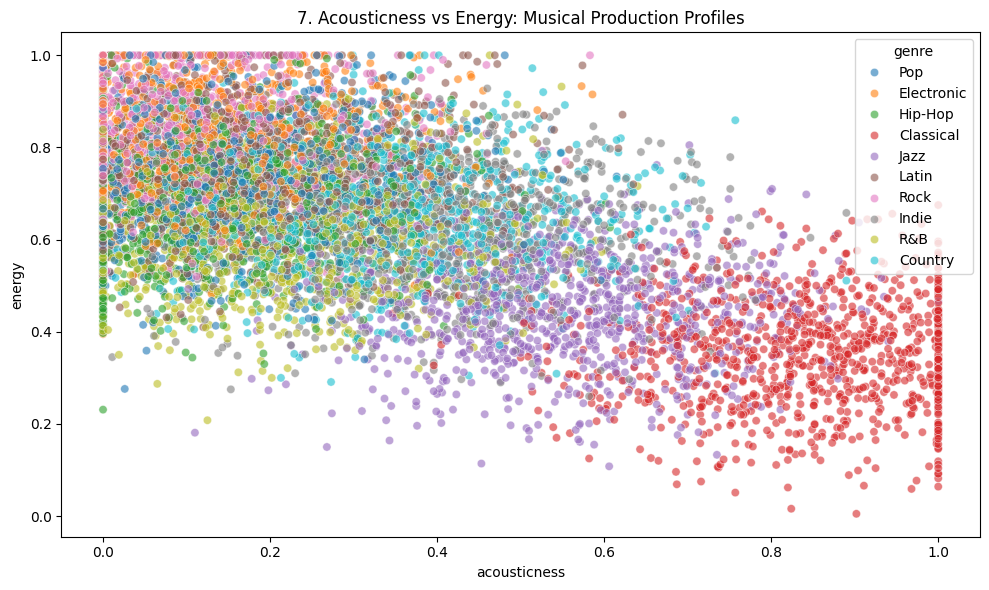

In [19]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='acousticness', y='energy', hue='genre', alpha=0.6)
plt.title(f'{plot_no}. Acousticness vs Energy: Musical Production Profiles')
show_fig()
plot_no += 1

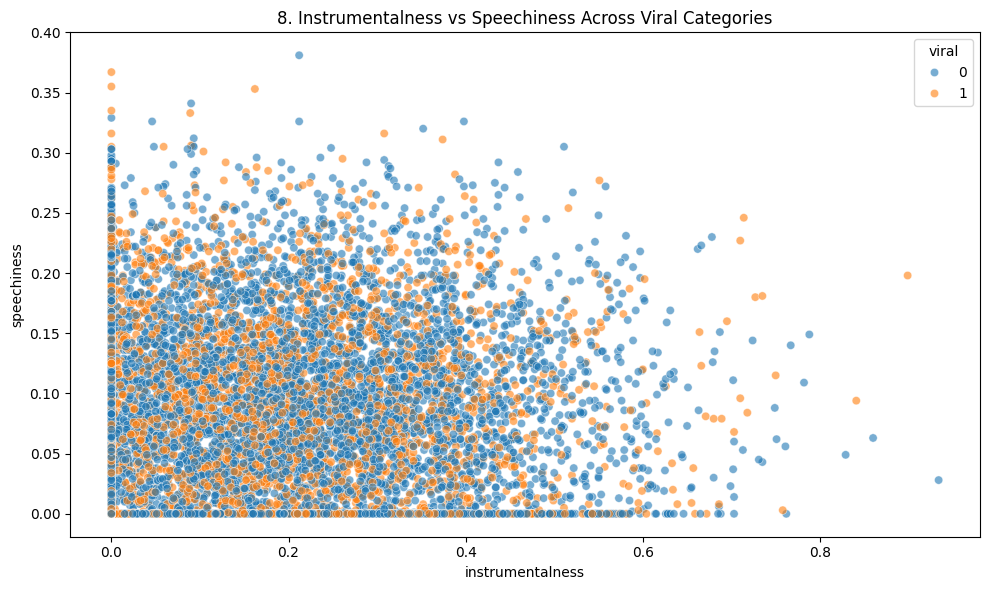

In [20]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='instrumentalness', y='speechiness', hue='viral', alpha=0.6)
plt.title(f'{plot_no}. Instrumentalness vs Speechiness Across Viral Categories')
show_fig()
plot_no += 1

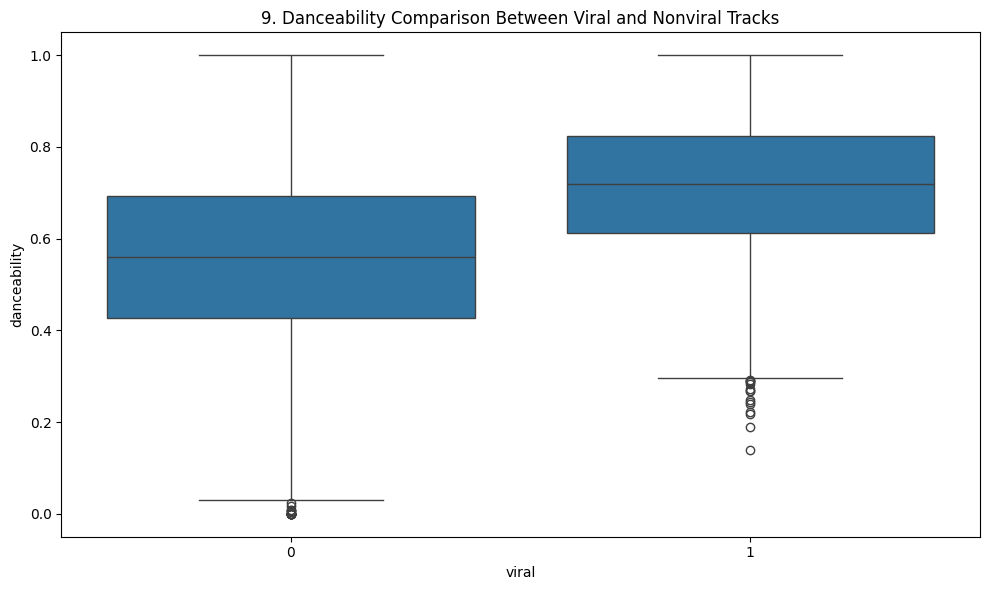

In [21]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='viral', y='danceability')
plt.title(f'{plot_no}. Danceability Comparison Between Viral and Nonviral Tracks')
show_fig()
plot_no += 1

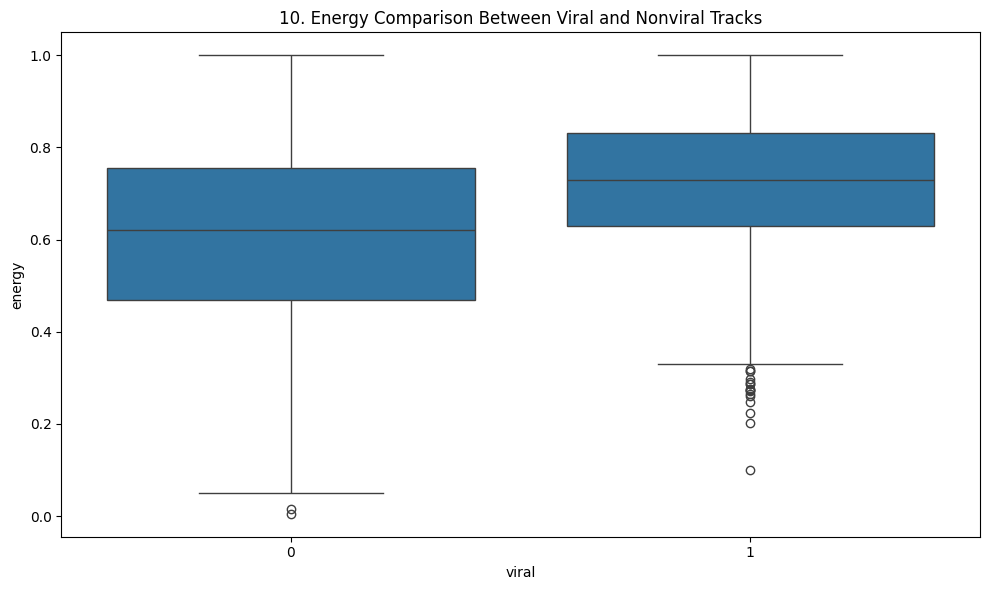

In [22]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='viral', y='energy')
plt.title(f'{plot_no}. Energy Comparison Between Viral and Nonviral Tracks')
show_fig()
plot_no += 1

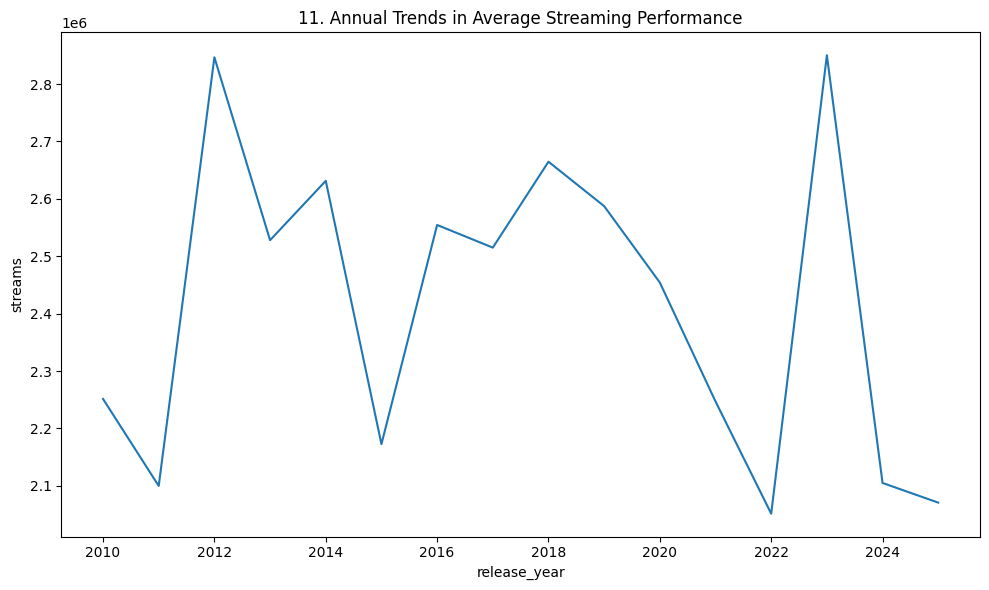

In [23]:
fig = plt.figure(figsize=(10,6))
sns.lineplot(data=df, x='release_year', y='streams', errorbar=None, estimator='mean')
plt.title(f'{plot_no}. Annual Trends in Average Streaming Performance')
show_fig()
plot_no += 1

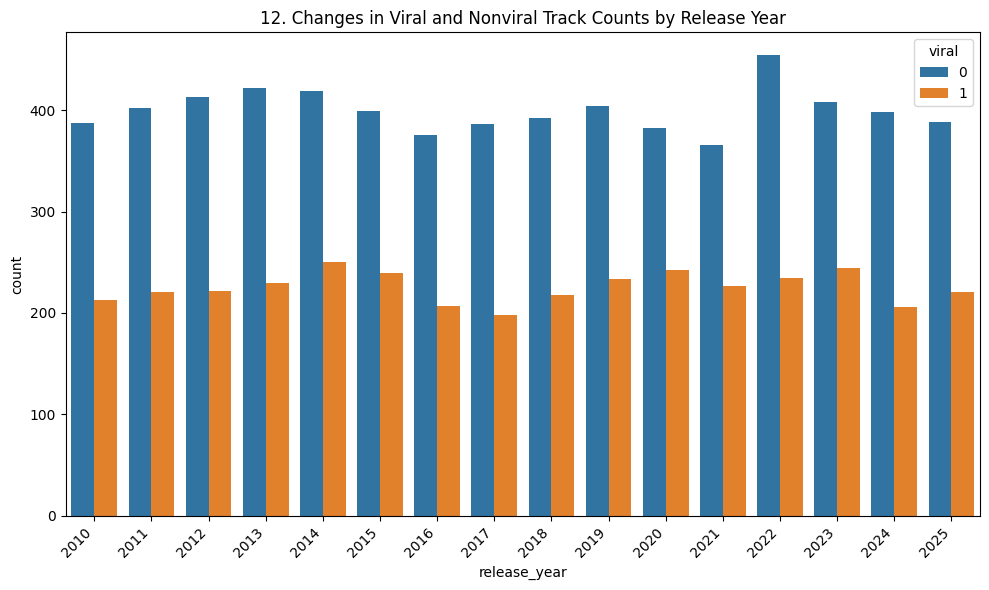

In [24]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='release_year', hue='viral')
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Changes in Viral and Nonviral Track Counts by Release Year')
show_fig()
plot_no += 1

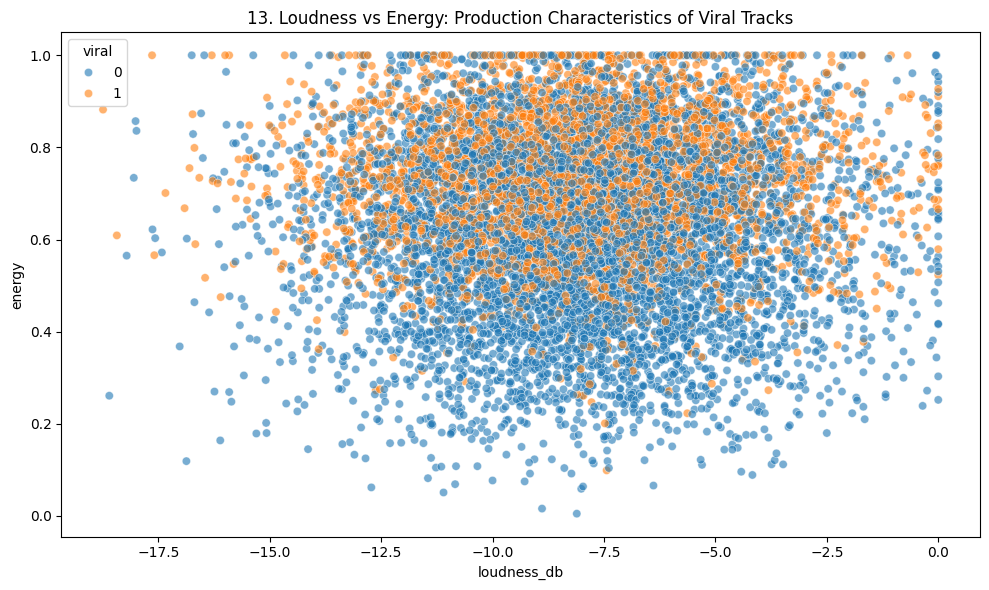

In [25]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='loudness_db', y='energy', hue='viral', alpha=0.6)
plt.title(f'{plot_no}. Loudness vs Energy: Production Characteristics of Viral Tracks')
show_fig()
plot_no += 1

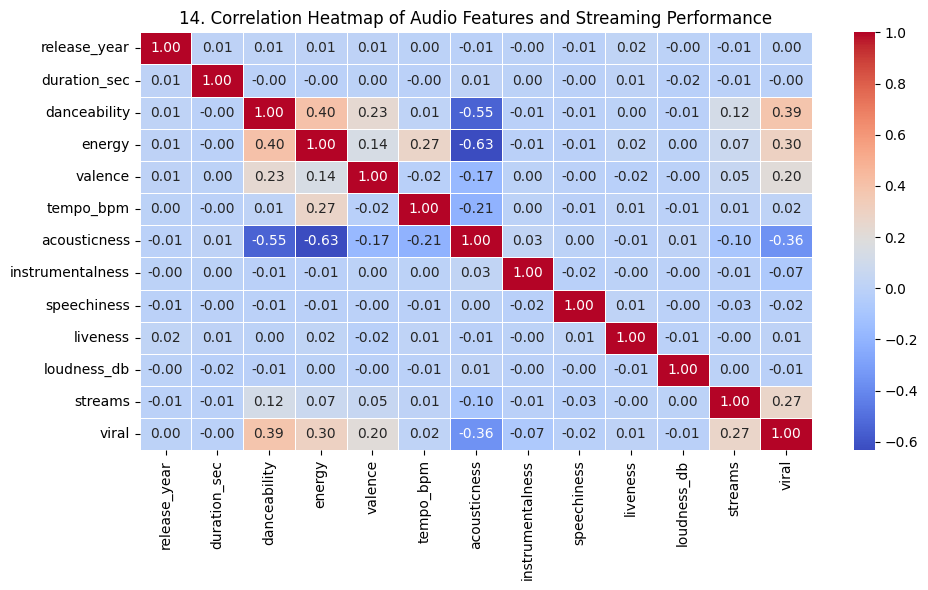

In [26]:
fig = plt.figure(figsize=(10,6))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Audio Features and Streaming Performance')
show_fig()
plot_no += 1

# Model Training

## Remove rows where the target is missing

In [27]:
data = df.dropna(subset=['viral']).copy()

## Select audio features and exclude identifiers and data leakage

In [28]:
X = data.drop(columns=['viral', 'track_id', 'track_name', 'artist'], errors='ignore')
y = data['viral'].astype(int)

## Identify numerical and categorical features

In [29]:
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()

## Prepare numerical features with missing-value imputation and scaling

In [30]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

## Prepare categorical features with imputation and one-hot encoding

In [31]:
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

## Combine numerical and categorical preprocessing

In [32]:
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

## Split the dataset into training and testing sets

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Build a logistic regression classification pipeline

In [34]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000, class_weight='balanced'))
])

## Train the model

In [35]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['release_year',
                                                   'duration_sec',
                                                   'danceability', 'energy',
                                                   'valence', 'tempo_bpm',
                                                   'acousticness',
                                                   'instrumentalness',
                                                   'speechiness', 'liveness',
                                                   'loudness_db', 'streams']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['genre'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=2000))])

## Predict viral labels for unseen test data

In [36]:
y_pred = model.predict(X_test)

## Print model accuracy and classification metrics

In [37]:
print(f"Model Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy: 0.8075

Classification Report:

              precision    recall  f1-score   support

           0       0.88      0.81      0.84      1279
           1       0.71      0.80      0.75       721

    accuracy                           0.81      2000
   macro avg       0.79      0.81      0.80      2000
weighted avg       0.82      0.81      0.81      2000



## Plot the confusion matrix

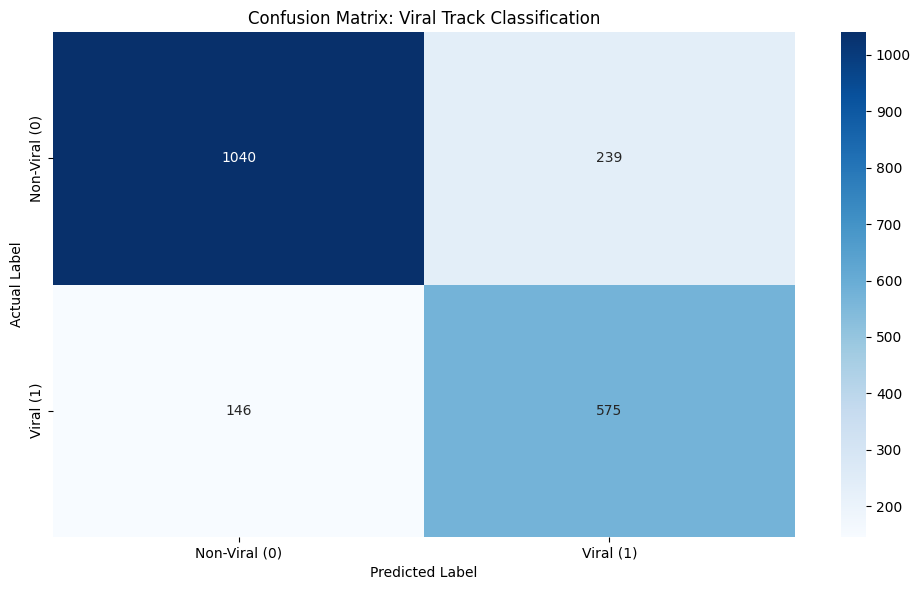

In [38]:
fig = plt.figure(figsize=(10, 6))
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Viral (0)', 'Viral (1)'],
    yticklabels=['Non-Viral (0)', 'Viral (1)']
)
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix: Viral Track Classification')
plt.tight_layout()
plt.show()

## Plot actual versus predicted classifications for a test sample
results = pd.DataFrame({
    'Actual': y_test.to_numpy(),
    'Predicted': y_pred
}).reset_index(drop=True).head(50)